## **Import Library**

In [7]:
#%pip install -q torchsummary

import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torch.nn.init as init

import random

from torchsummary import summary

# Check if GPU is available
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

In [8]:
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

# Đảm bảo kết quả lặp lại với cuDNN
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

## **Load CIFAR10**

In [9]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.485, 0.456, 0.406),
        std=(0.229, 0.224, 0.225)
    )
])


torchvision.datasets.CIFAR10.url = 'https://huggingface.co/datasets/MIT-OL-AI-D/cifar-10-python/resolve/main/cifar-10-python.tar.gz'

trainset = torchvision.datasets.CIFAR10(root='../../../data', train=True, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=1024, num_workers=10, shuffle=True, drop_last=True)

testset = torchvision.datasets.CIFAR10(root='../../../data', train=False, download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=1024, num_workers=10, shuffle=False)

## **Model - Deeper model**

In [10]:
class CustomModel(nn.Module):
    def __init__(self):
        super(CustomModel, self).__init__()

        # 4 conv, baseline: (32, 64, 128, 256)
        self.features = nn.Sequential(
            # 3x32x32 -> 64x32x32
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # 64x32x32 -> 128x32x32
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # MaxPool: 128x32x32 -> 256x16x16
            nn.MaxPool2d(kernel_size=2, stride=2),

            # 128x16x16 -> 128x16x16
            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # 256x16x16 -> 512x16x16
            nn.Conv2d(256, 512, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # MaxPool: 512x16x16 -> 512x8x8
            nn.MaxPool2d(kernel_size=2, stride=2),
        )

        # Sau features: 256 x 8 x 8 = 16384
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 8 * 8, 256),
            nn.ReLU(inplace=True),
            nn.Linear(256, 10)  # CIFAR-10
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = CustomModel().to(device)
summary(model, (3, 32, 32))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 32, 32]           1,792
              ReLU-2           [-1, 64, 32, 32]               0
            Conv2d-3          [-1, 128, 32, 32]          73,856
              ReLU-4          [-1, 128, 32, 32]               0
         MaxPool2d-5          [-1, 128, 16, 16]               0
            Conv2d-6          [-1, 256, 16, 16]         295,168
              ReLU-7          [-1, 256, 16, 16]               0
            Conv2d-8          [-1, 512, 16, 16]       1,180,160
              ReLU-9          [-1, 512, 16, 16]               0
        MaxPool2d-10            [-1, 512, 8, 8]               0
          Flatten-11                [-1, 32768]               0
           Linear-12                  [-1, 256]       8,388,864
             ReLU-13                  [-1, 256]               0
           Linear-14                   

## **Loss, Optimizer, and Evaluation Function**

In [11]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=1e-3)

In [12]:
def evaluate(model, testloader, criterion):
    model.eval()
    test_loss = 0.0
    running_correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in testloader:
            images, labels = images.to(device), labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)
            test_loss += loss.item()

            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            running_correct += (predicted == labels).sum().item()

    accuracy = 100 * running_correct / total
    test_loss = test_loss / len(testloader)
    return test_loss, accuracy

## **Training model**

In [13]:
train_losses = []
train_accuracies = []
test_losses = []
test_accuracies = []
max_epoch = 20

In [14]:
for epoch in range(max_epoch):
    model.train()
    running_loss = 0.0
    running_correct = 0
    total = 0

    for i, (inputs, labels) in enumerate(trainloader, 0):
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        running_loss += loss.item()

        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        running_correct += (predicted == labels).sum().item()

        loss.backward()
        optimizer.step()

    epoch_accuracy = 100 * running_correct / total
    epoch_loss = running_loss / (i + 1)

    test_loss, test_accuracy = evaluate(model, testloader, criterion)
    print(f"Epoch [{epoch + 1}/{max_epoch}], Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.2f}%, Test Loss: {test_loss:.4f}, Test Accuracy: {test_accuracy:.2f}%")

    train_losses.append(epoch_loss)
    train_accuracies.append(epoch_accuracy)
    test_losses.append(test_loss)
    test_accuracies.append(test_accuracy)

Epoch [1/20], Loss: 1.8905, Accuracy: 30.75%, Test Loss: 1.4761, Test Accuracy: 46.32%
Epoch [2/20], Loss: 1.3203, Accuracy: 52.17%, Test Loss: 1.2309, Test Accuracy: 56.38%
Epoch [3/20], Loss: 1.0856, Accuracy: 61.44%, Test Loss: 0.9956, Test Accuracy: 64.37%
Epoch [4/20], Loss: 0.9214, Accuracy: 67.56%, Test Loss: 0.8864, Test Accuracy: 68.62%
Epoch [5/20], Loss: 0.7848, Accuracy: 72.49%, Test Loss: 0.8213, Test Accuracy: 70.99%
Epoch [6/20], Loss: 0.6688, Accuracy: 76.74%, Test Loss: 0.7371, Test Accuracy: 73.92%
Epoch [7/20], Loss: 0.5864, Accuracy: 79.59%, Test Loss: 0.6947, Test Accuracy: 75.95%
Epoch [8/20], Loss: 0.4872, Accuracy: 83.06%, Test Loss: 0.6784, Test Accuracy: 77.36%
Epoch [9/20], Loss: 0.4060, Accuracy: 85.88%, Test Loss: 0.6875, Test Accuracy: 77.17%
Epoch [10/20], Loss: 0.3211, Accuracy: 88.94%, Test Loss: 0.6936, Test Accuracy: 78.09%
Epoch [11/20], Loss: 0.2274, Accuracy: 92.34%, Test Loss: 0.7418, Test Accuracy: 78.11%
Epoch [12/20], Loss: 0.1677, Accuracy: 94

## **Plotting Curves**

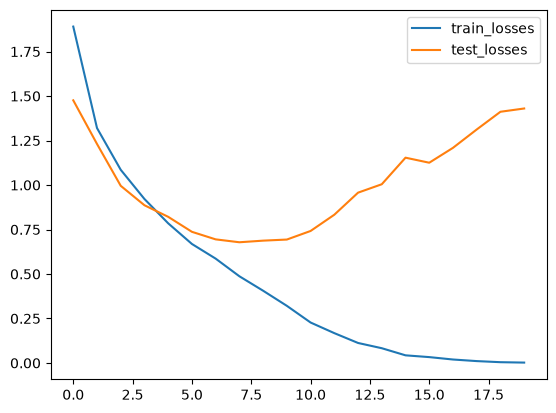

In [15]:
plt.plot(train_losses, label='train_losses')
plt.plot(test_losses, label='test_losses')
plt.legend()

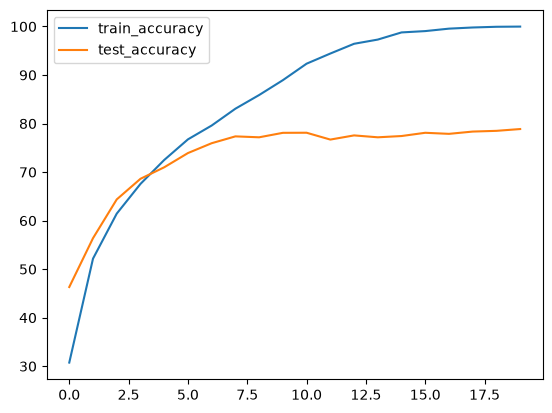

In [16]:
plt.plot(train_accuracies, label='train_accuracy')
plt.plot(test_accuracies, label='test_accuracy')
plt.legend()